In [1]:
import spatialdata as sd
import decoupler as dc
from spatialdata_io import xenium

import numpy as np
import pandas as pd
import scipy.sparse as sp


import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad

import scanpy as sc

import squidpy as sq

sc.set_figure_params(figsize=(8,8))
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['font.size'] = 10              # Universal font size
mpl.rcParams['axes.titlesize'] = 10          # Title size
mpl.rcParams['axes.labelsize'] = 10          # X and Y label size
mpl.rcParams['xtick.labelsize'] = 10         # X tick label size
mpl.rcParams['ytick.labelsize'] = 10        # Y tick label size
mpl.rcParams['legend.fontsize'] = 10         # Legend font size
mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'


import os

import sys
plt.style.use('default')

/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/exports/archive/hg-exon-skip/Qirong/conda/envs/spatialdata/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
Sample_895=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_895.h5ad")
Sample_894=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_894.h5ad")
Sample_898=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_898.h5ad")


Sample_896=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_896.h5ad")
Sample_897=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_897.h5ad")
Sample_18=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_18.h5ad")

Sample_886=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_886.h5ad")
Sample_890=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_890.h5ad")
Sample_891=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_891.h5ad")


Sample_4=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_4.h5ad")
Sample_5=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_5.h5ad")
Sample_3=sc.read_h5ad("/exports/archive/hg-exon-skip/Qirong/Xenium/scanpy_object/Sample_3.h5ad")


In [3]:
adata = Sample_895.concatenate(Sample_894,Sample_898,Sample_896,Sample_897,Sample_18,Sample_886,Sample_890,Sample_891,Sample_4,Sample_5,Sample_3)

/tmp/ipykernel_2820243/3560033395.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = Sample_895.concatenate(Sample_894,Sample_898,Sample_896,Sample_897,Sample_18,Sample_886,Sample_890,Sample_891,Sample_4,Sample_5,Sample_3)


In [22]:
adata = Sample_895.concatenate(Sample_894,Sample_898,Sample_896,Sample_897,Sample_18)

/tmp/ipykernel_3934952/4106169230.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = Sample_895.concatenate(Sample_894,Sample_898,Sample_896,Sample_897,Sample_18)


In [3]:
adata = Sample_895.concatenate(Sample_894,Sample_898)

/tmp/ipykernel_3934952/1532990001.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = Sample_895.concatenate(Sample_894,Sample_898)


In [4]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

In [5]:
gene1 = "Dp427c"
gene2 = "Dystrophin_Exon2_29"

# Check where the genes are
use_raw = adata.raw is not None and gene1 in adata.raw.var_names and gene2 in adata.raw.var_names
X = adata.raw.X if use_raw else adata.X
var_names = adata.raw.var_names if use_raw else adata.var_names

# Convert to DataFrame
if hasattr(X, "toarray"):
    X = X.toarray()
df_expr = pd.DataFrame(X, columns=var_names, index=adata.obs_names)

# Add region and class
df_expr["Region"] = adata.obs["Region"].values
df_expr["Class"] = adata.obs["Class"].values

# Group by region × class and compute mean (or sum)
grouped = df_expr.groupby(["Region", "Class"])[[gene1, gene2]].mean().dropna()

/tmp/ipykernel_3934952/1833645563.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = df_expr.groupby(["Region", "Class"])[[gene1, gene2]].mean().dropna()


In [6]:
# List of genes to analyze
genes = ['Dp427c', 'Dp427m', 'Dp427p',"Dp427p2","Dp71_Dp40_firstexon","Dp40"]


# Ensure all genes are in the dataset
genes = [g for g in genes if g in adata.var_names]

# Extract expression matrix for selected genes
expr = adata[:, genes].to_df()

# Add metadata: Sample and Region
expr['Sample'] = adata.obs['Sample'].values
expr['Region'] = adata.obs['Region'].values  # Make sure 'Region' exists in adata.obs

# Compute pseudobulk: mean expression per gene per region and sample
pseudobulk = expr.groupby(['Region', 'Sample']).mean().reset_index()

# Convert to long format for plotting
pseudobulk_long = pd.melt(
    pseudobulk,
    id_vars=['Region', 'Sample'],
    var_name='Gene',
    value_name='Expression'
)



/tmp/ipykernel_3934952/1884573272.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pseudobulk = expr.groupby(['Region', 'Sample']).mean().reset_index()


In [7]:
pseudobulk_long 

,Region,Sample,Gene,Expression
0,Cortex L1,894,Dp427c,0.137108
1,Cortex L1,895,Dp427c,0.126076
2,Cortex L1,898,Dp427c,0.134826
3,Cortex L2/3,894,Dp427c,0.361668
4,Cortex L2/3,895,Dp427c,0.338703
...,...,...,...,...
445,Fiber tracts,895,Dp40,0.048422
446,Fiber tracts,898,Dp40,0.052468
447,Unassigned,894,Dp40,0.083481
448,Unassigned,895,Dp40,0.083983


In [8]:
sample_to_group = {
    "895": 'Wildtype', "894": 'Wildtype', "898": 'Wildtype',
    "896": 'mdx52', "897": 'mdx52', "18": 'mdx52',
    "886": 'tcDNA', "890": 'tcDNA', "891":'tcDNA',
    "4": 'U7ex51', "5": 'U7ex51', "3": 'U7ex51'
}

In [9]:
mapping_df = pd.DataFrame(list(sample_to_group.items()), columns=['Sample', 'group'])

In [10]:
main_df = pseudobulk_long.merge(mapping_df, on='Sample', how='left')

In [11]:
main_df

,Region,Sample,Gene,Expression,group
0,Cortex L1,894,Dp427c,0.137108,Wildtype
1,Cortex L1,895,Dp427c,0.126076,Wildtype
2,Cortex L1,898,Dp427c,0.134826,Wildtype
3,Cortex L2/3,894,Dp427c,0.361668,Wildtype
4,Cortex L2/3,895,Dp427c,0.338703,Wildtype
...,...,...,...,...,...
445,Fiber tracts,895,Dp40,0.048422,Wildtype
446,Fiber tracts,898,Dp40,0.052468,Wildtype
447,Unassigned,894,Dp40,0.083481,Wildtype
448,Unassigned,895,Dp40,0.083983,Wildtype


In [12]:
main_df.to_excel("/exports/humgen/qmao/isoforms_expression_group.xlsx", index=False)

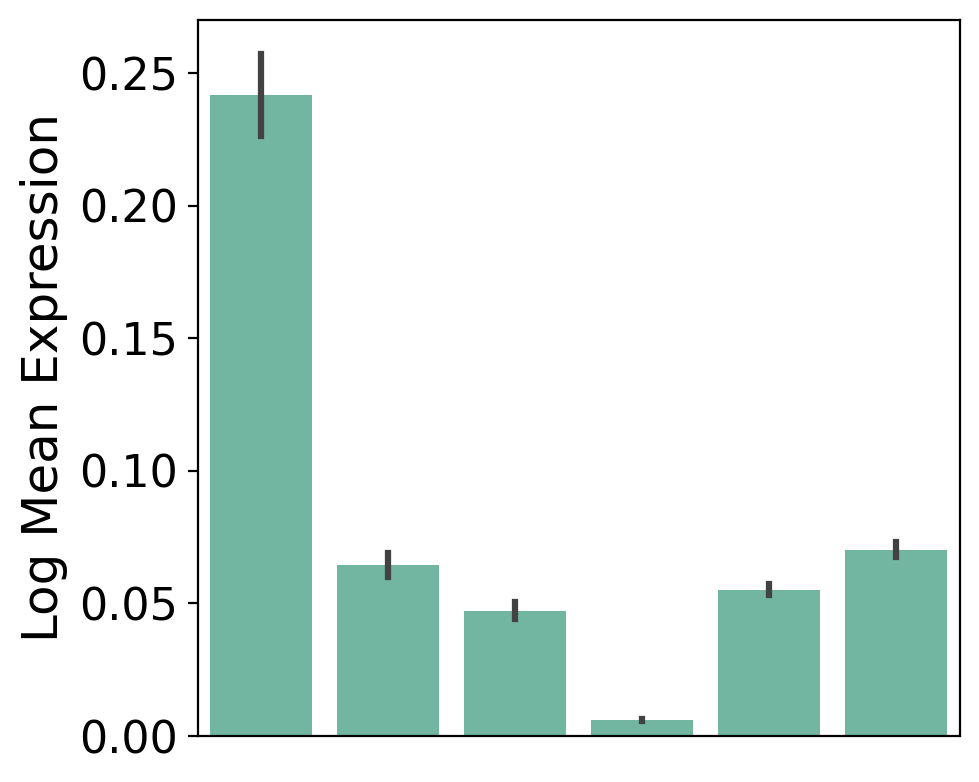

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(5, 4))
sns.barplot(data=pseudobulk_long, x='Gene', y='Expression',color="#66C2A5",errorbar=('se'))
##sns.stripplot(
##    data=pseudobulk_long,
##     x='Gene',y="Expression",
##    dodge=True, color='black', size=7, alpha=0.6
#3)
plt.ylabel("Log Mean Expression", fontsize=18)
plt.xlabel("")
plt.xticks([])
plt.yticks(fontsize=16)
plt.tight_layout()
plt.savefig("/exports/humgen/qmao/WT_multiple_isoforms.svg",format="svg", dpi=300, bbox_inches='tight')
plt.show()

In [47]:
adata = Sample_895.concatenate(Sample_894,Sample_898,Sample_896,Sample_897,Sample_18)

/tmp/ipykernel_3934952/4106169230.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = Sample_895.concatenate(Sample_894,Sample_898,Sample_896,Sample_897,Sample_18)


In [48]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

In [24]:
df = adata.obs.copy()
df["Dystrophin_Exon2_29"] = adata[:, "Dystrophin_Exon2_29"].X.toarray().flatten()

# Step 1: Group by Sample and Region to get mean expression
grouped_df = df.groupby(["Sample", "Region"])["Dystrophin_Exon2_29"].mean().reset_index()

# Step 2: Map Group per Sample from original df
sample_to_group = df.drop_duplicates("Sample")[["Sample", "Group"]].set_index("Sample")["Group"]
grouped_df["Group"] = grouped_df["Sample"].map(sample_to_group)

/tmp/ipykernel_3934952/52655588.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_df = df.groupby(["Sample", "Region"])["Dystrophin_Exon2_29"].mean().reset_index()


In [25]:
grouped_df

,Sample,Region,Dystrophin_Exon2_29,Group
0,18,Cortex L1,0.369004,mdx52
1,18,Cortex L2/3,0.936712,mdx52
2,18,Cortex L4,0.833832,mdx52
3,18,Cortex L5,0.821914,mdx52
4,18,Cortex L6a,1.021824,mdx52
...,...,...,...,...
145,898,Medial amygdalar nucleus,0.909169,WT
146,898,Caudoputamen,0.547343,WT
147,898,Ventricular system,0.371744,WT
148,898,Fiber tracts,0.059489,WT


In [26]:
grouped_df.to_excel('/exports/humgen/qmao/Dystrophin_Exon2_29_Region.xlsx', index=False)

In [27]:
import matplotlib.font_manager as fm

available_fonts = sorted({fm.FontProperties(fname=path).get_name()
                          for path in fm.findSystemFonts(fontpaths=None)})
print(available_fonts)

['C059', 'Cantarell', 'D050000L', 'DejaVu Sans', 'DejaVu Sans Mono', 'Droid Sans', 'Droid Sans Arabic', 'Droid Sans Armenian', 'Droid Sans Devanagari', 'Droid Sans Ethiopic', 'Droid Sans Fallback', 'Droid Sans Georgian', 'Droid Sans Hebrew', 'Droid Sans Japanese', 'Droid Sans Tamil', 'Droid Sans Thai', 'FontAwesome', 'Liberation Mono', 'Nimbus Mono PS', 'Nimbus Roman', 'Nimbus Sans', 'Nimbus Sans Narrow', 'P052', 'URW Bookman', 'URW Gothic', 'Z003']


In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Settings
column_widths = {1: 3.5, 1.5: 5.0, 2: 7.3}  # in inches
column = 1  # choose 1, 1.5, or 2
fig_width = column_widths[column]
fig_height = fig_width * 0.618  # golden ratio for aesthetics, or adjust manually

# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 6,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6,
    'figure.figsize': (fig_width, fig_height)
})

mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'

# 1. Copy obs and add XX gene expression
df = adata.obs.copy()
df["Dystrophin_Exon2_29"] = adata[:, "Dystrophin_Exon2_29"].X.toarray().flatten()

# 2. Filter to keep only positive expression values
plt.figure(figsize=(3.2, 4.5))
# 3. Compute mean XX expression per Sample

# Step 1: Group by Sample and Region to get mean expression
grouped_df = df.groupby(["Sample", "Region"])["Dystrophin_Exon2_29"].mean().reset_index()

# Step 2: Map Group per Sample from original df
sample_to_group = df.drop_duplicates("Sample")[["Sample", "Group"]].set_index("Sample")["Group"]
grouped_df["Group"] = grouped_df["Sample"].map(sample_to_group)

# 4. Plot: boxplot + dotplot (stripplot)

ax = sns.boxplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Region", hue="Group",
            palette=["#66C2A5","#FC8D62"], dodge=True, showfliers=False,width=0.8,linewidth=0.3,fliersize=0)

sns.stripplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Region", hue="Group",orient="h",dodge=True, color="black", size=1, alpha=0.6)

# 5. Prepare statistical comparisons
group_list = grouped_df["Group"].unique()
if len(group_list) != 2:
    raise ValueError("Statannotations: This script assumes exactly two groups.")

regions = grouped_df["Region"].unique()


# 6. Clean up legend
handles, labels = ax.get_legend_handles_labels()
n = len(group_list)
plt.legend(handles[:n], labels[:n], title="Group",loc='lower right')

# 7. Tweak axis

plt.xlabel('Log Mean Expression of Dystrophin_Exon2_29')
plt.ylabel('Region')



# Extend y-axis to make space for annotation
##x_max = grouped_df["Dp427c"].quantile(0.99)
##plt.xlim(0, x_max * 1.3)  # 30% headroom for stars



plt.tight_layout()
plt.savefig(f"/exports/humgen/qmao/Dystrophin_Exon2_29_Region_boxplot.svg",format="svg", dpi=300, bbox_inches='tight')
plt.close()

/tmp/ipykernel_3934952/1144583102.py:36: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_df = df.groupby(["Sample", "Region"])["Dystrophin_Exon2_29"].mean().reset_index()
/tmp/ipykernel_3934952/1144583102.py:47: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Region", hue="Group",orient="h",dodge=True, color="black", size=1, alpha=0.6)


In [51]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Settings
column_widths = {1: 3.5, 1.5: 5.0, 2: 7.3}  # in inches
column = 1  # choose 1, 1.5, or 2
fig_width = column_widths[column]
fig_height = fig_width * 0.618  # golden ratio for aesthetics, or adjust manually

# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 6,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6,
    'figure.figsize': (fig_width, fig_height)
})

mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'

# 1. Copy obs and add XX gene expression
df = adata.obs.copy()
df["Dystrophin_Exon2_29"] = adata[:, "Dystrophin_Exon2_29"].X.toarray().flatten()

# 2. Filter to keep only positive expression values
plt.figure(figsize=(3.2, 4.5))
# 3. Compute mean XX expression per Sample

# Step 1: Group by Sample and Region to get mean expression
grouped_df = df.groupby(["Sample", "Class"])["Dystrophin_Exon2_29"].mean().reset_index()

# Step 2: Map Group per Sample from original df
sample_to_group = df.drop_duplicates("Sample")[["Sample", "Group"]].set_index("Sample")["Group"]
grouped_df["Group"] = grouped_df["Sample"].map(sample_to_group)

# 4. Plot: boxplot + dotplot (stripplot)

ax = sns.boxplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Class", hue="Group",
            palette=["#66C2A5","#FC8D62"], dodge=True, showfliers=False,width=0.8,linewidth=0.3,fliersize=0)

sns.stripplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Class", hue="Group",orient="h",dodge=True, color="black", size=3, alpha=0.6)

# 5. Prepare statistical comparisons
group_list = grouped_df["Group"].unique()
if len(group_list) != 2:
    raise ValueError("Statannotations: This script assumes exactly two groups.")

regions = grouped_df["Class"].unique()


# 6. Clean up legend
handles, labels = ax.get_legend_handles_labels()
n = len(group_list)
plt.legend(handles[:n], labels[:n], title="Group",loc='lower right')

# 7. Tweak axis

plt.xlabel('Log Mean Expression of Dystrophin_Exon2_29')
plt.ylabel('Region')



# Extend y-axis to make space for annotation
##x_max = grouped_df["Dp427c"].quantile(0.99)
##plt.xlim(0, x_max * 1.3)  # 30% headroom for stars



plt.tight_layout()
plt.savefig(f"/exports/humgen/qmao/Dystrophin_Exon2_29_Class_boxplot.svg",format="svg", dpi=300, bbox_inches='tight')
plt.close()

/tmp/ipykernel_3934952/2938419580.py:36: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_df = df.groupby(["Sample", "Class"])["Dystrophin_Exon2_29"].mean().reset_index()
/tmp/ipykernel_3934952/2938419580.py:47: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Class", hue="Group",orient="h",dodge=True, color="black", size=3, alpha=0.6)


In [55]:
from statannotations.Annotator import Annotator
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 6,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6,
    'figure.figsize': (fig_width, fig_height)
})

mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'


# 1. Copy obs and add XX gene expression
df = adata.obs.copy()
df["Dystrophin_Exon2_29"] = adata[:, "Dystrophin_Exon2_29"].X.toarray().flatten()

# 2. Filter to keep only positive expression values

# 3. Compute mean XX expression per Sample

# Step 1: Group by Sample and Region to get mean expression
grouped_df = df.groupby(["Sample", "Region"])["Dystrophin_Exon2_29"].mean().reset_index()

# Step 2: Map Group per Sample from original df
sample_to_group = df.drop_duplicates("Sample")[["Sample", "Group"]].set_index("Sample")["Group"]
grouped_df["Group"] = grouped_df["Sample"].map(sample_to_group)

# 4. Plot: boxplot + dotplot (stripplot)
plt.figure(figsize=(4.2, 6.6))

ax = sns.boxplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Region", hue="Group",
            palette=["#66C2A5","#FC8D62"], dodge=True, showfliers=False)

sns.stripplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Region", hue="Group",orient="h",dodge=True, color="black", size=3, alpha=0.6)

# 5. Prepare statistical comparisons
group_list = grouped_df["Group"].unique()
if len(group_list) != 2:
    raise ValueError("Statannotations: This script assumes exactly two groups.")

regions = grouped_df["Region"].unique()
pairs = [((region, group_list[0]), (region, group_list[1])) for region in regions]

annotator = Annotator(ax, pairs, data=grouped_df, x="Dystrophin_Exon2_29", y="Region",
                      hue="Group",orient="h",order=regions.tolist(), hue_order=group_list.tolist())

# Configure for unified clean position
annotator.configure(
    test='t-test_ind',
    text_format='star',
    loc='outside',               # Place annotations above plot
    verbose=0,
    line_offset=0.05,            # Vertical offset from top of box
    line_offset_to_group=True,   # Offset relative to group position
    line_height=0.01,
    fontsize=5,
    comparisons_correction="BH", correction_format="replace"
).apply_and_annotate()




# 6. Clean up legend
handles, labels = ax.get_legend_handles_labels()
n = len(group_list)
plt.legend(handles[:n], labels[:n], title="Group",loc='lower right')

# 7. Tweak axis

plt.xlabel('Log Mean Expression', fontsize=6)
plt.ylabel('Region', fontsize=6)
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)


# Extend y-axis to make space for annotation
##x_max = grouped_df["Dp427c"].quantile(0.99)
##plt.xlim(0, x_max * 1.3)  # 30% headroom for stars



plt.tight_layout()
plt.savefig(f"/exports/humgen/qmao/Dystrophin_Exon2_29_Region_boxplot.svg", dpi=300, bbox_inches='tight')
plt.close()


/tmp/ipykernel_3934952/2523658018.py:32: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_df = df.groupby(["Sample", "Region"])["Dystrophin_Exon2_29"].mean().reset_index()
/tmp/ipykernel_3934952/2523658018.py:44: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Region", hue="Group",orient="h",dodge=True, color="black", size=3, alpha=0.6)


In [58]:
from statannotations.Annotator import Annotator
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 6,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6,
    'figure.figsize': (fig_width, fig_height)
})

mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'

# 1. Copy obs and add XX gene expression
df = adata.obs.copy()
df["Dystrophin_Exon2_29"] = adata[:, "Dystrophin_Exon2_29"].X.toarray().flatten()

# 2. Filter to keep only positive expression values

# 3. Compute mean XX expression per Sample

# Step 1: Group by Sample and Region to get mean expression
grouped_df = df.groupby(["Sample", "Class"])["Dystrophin_Exon2_29"].mean().reset_index()

# Step 2: Map Group per Sample from original df
sample_to_group = df.drop_duplicates("Sample")[["Sample", "Group"]].set_index("Sample")["Group"]
grouped_df["Group"] = grouped_df["Sample"].map(sample_to_group)

# 4. Plot: boxplot + dotplot (stripplot)
plt.figure(figsize=(3.2,3))

ax = sns.boxplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Class", hue="Group",
            palette=["#66C2A5","#FC8D62"], dodge=True, showfliers=False)

sns.stripplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Class", hue="Group",orient="h",dodge=True, color="black", size=2, alpha=0.6)

# 5. Prepare statistical comparisons
group_list = grouped_df["Group"].unique()
if len(group_list) != 2:
    raise ValueError("Statannotations: This script assumes exactly two groups.")

regions = grouped_df["Class"].unique()
pairs = [((region, group_list[0]), (region, group_list[1])) for region in regions]

annotator = Annotator(ax, pairs, data=grouped_df, x="Dystrophin_Exon2_29", y="Class",
                      hue="Group",orient="h",order=regions.tolist(), hue_order=group_list.tolist())

# Configure for unified clean position
annotator.configure(
    test='t-test_ind',
    text_format='star',
    loc='outside',               # Place annotations above plot
    verbose=0,
    line_offset=0.05,            # Vertical offset from top of box
    line_offset_to_group=True,   # Offset relative to group position
    line_height=0.01,
    fontsize=5,
    comparisons_correction="BH", correction_format="replace"
).apply_and_annotate()




# 6. Clean up legend
handles, labels = ax.get_legend_handles_labels()
n = len(group_list)
plt.legend(handles[:n], labels[:n], title="Group",loc='lower right')

# 7. Tweak axis

plt.xlabel('Log Mean Expression', fontsize=6)
plt.ylabel('Cell Type', fontsize=6)
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)


# Extend y-axis to make space for annotation
##x_max = grouped_df["Dp427c"].quantile(0.99)
##plt.xlim(0, x_max * 1.075)  # 30% headroom for stars



plt.tight_layout()
plt.savefig(f"/exports/humgen/qmao/Dystrophin_Exon2_29_Class_boxplot.svg", dpi=300, bbox_inches='tight')
plt.close()


/tmp/ipykernel_3934952/311046999.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_df = df.groupby(["Sample", "Class"])["Dystrophin_Exon2_29"].mean().reset_index()
/tmp/ipykernel_3934952/311046999.py:43: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=grouped_df, x="Dystrophin_Exon2_29", y="Class", hue="Group",orient="h",dodge=True, color="black", size=2, alpha=0.6)


In [ ]:
from statannotations.Annotator import Annotator
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Copy obs and add XX gene expression
df = adata.obs.copy()


gene_list = ["Dp427c", "Dp427m","Dp427p","Dp427p2","Dp71_Dp40_firstexon","Dp40",'DystrophinExon50_51',
     'DystrophinExon50_53',
     'DystrophinExon51_53',
     'Dystrophin_Exon2_29',
     'Dystrophin_Exon30_44',
     'Dystrophin_Exon45_49',
     'Dystrophin_Exon56_62',
     'Dystrophin_Exon79']

for gene in gene_list:

    df[gene] = adata[:, gene].X.toarray().flatten()

    # 2. Filter to keep only positive expression values

    # 3. Compute mean XX expression per Sample

    # Step 1: Group by Sample and Region to get mean expression
    grouped_df = df.groupby(["Sample", "Region"])[gene].mean().reset_index()

    # Step 2: Map Group per Sample from original df
    sample_to_group = df.drop_duplicates("Sample")[["Sample", "Group"]].set_index("Sample")["Group"]
    grouped_df["Group"] = grouped_df["Sample"].map(sample_to_group)

    # 4. Plot: boxplot + dotplot (stripplot)
    plt.figure(figsize=(12, 8))

    ax = sns.boxplot(data=grouped_df, x="Region", y=gene, hue="Group",
                palette="Set1", dodge=True, showfliers=False)

    sns.stripplot(data=grouped_df, x="Region", y=gene, hue="Group",
                  dodge=True, color="black", size=4, alpha=0.6)

    # 5. Prepare statistical comparisons
    group_list = grouped_df["Group"].unique()
    if len(group_list) != 2:
        raise ValueError("Statannotations: This script assumes exactly two groups.")

    regions = grouped_df["Region"].unique()
    pairs = [((region, group_list[0]), (region, group_list[1])) for region in regions]

    annotator = Annotator(ax, pairs, data=grouped_df, x="Region", y=gene,
                          hue="Group", order=regions.tolist(), hue_order=group_list.tolist())

    # Configure for unified clean position
    annotator.configure(
        test='t-test_ind',
        text_format='star',
        loc='outside',               # Place annotations above plot
        verbose=0,
        line_offset=0.05,            # Vertical offset from top of box
        line_offset_to_group=True,   # Offset relative to group position
        line_height=0.01,
        fontsize=10,
        comparisons_correction="BH"
    ).apply_and_annotate()

    # 6. Clean up legend
    handles, labels = ax.get_legend_handles_labels()
    n = len(group_list)
    plt.legend(handles[:n], labels[:n], title="Group")

    # 7. Tweak axis
    plt.xticks(rotation=90)

    # Extend y-axis to make space for annotation
    y_max = grouped_df[gene].quantile(0.99)
    plt.ylim(0, y_max * 1.25)  # 30% headroom for stars

    ##plt.title("Mean log expression of XX per sample with significance marks")
    plt.tight_layout()
    plt.show()

/tmp/ipykernel_3876617/500678277.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_df = df.groupby(["Sample", "Region_hlevel"])["Dp427c"].mean().reset_index()
/tmp/ipykernel_3876617/500678277.py:27: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=grouped_df, x="Region_hlevel", y="Dp427c", hue="Group",


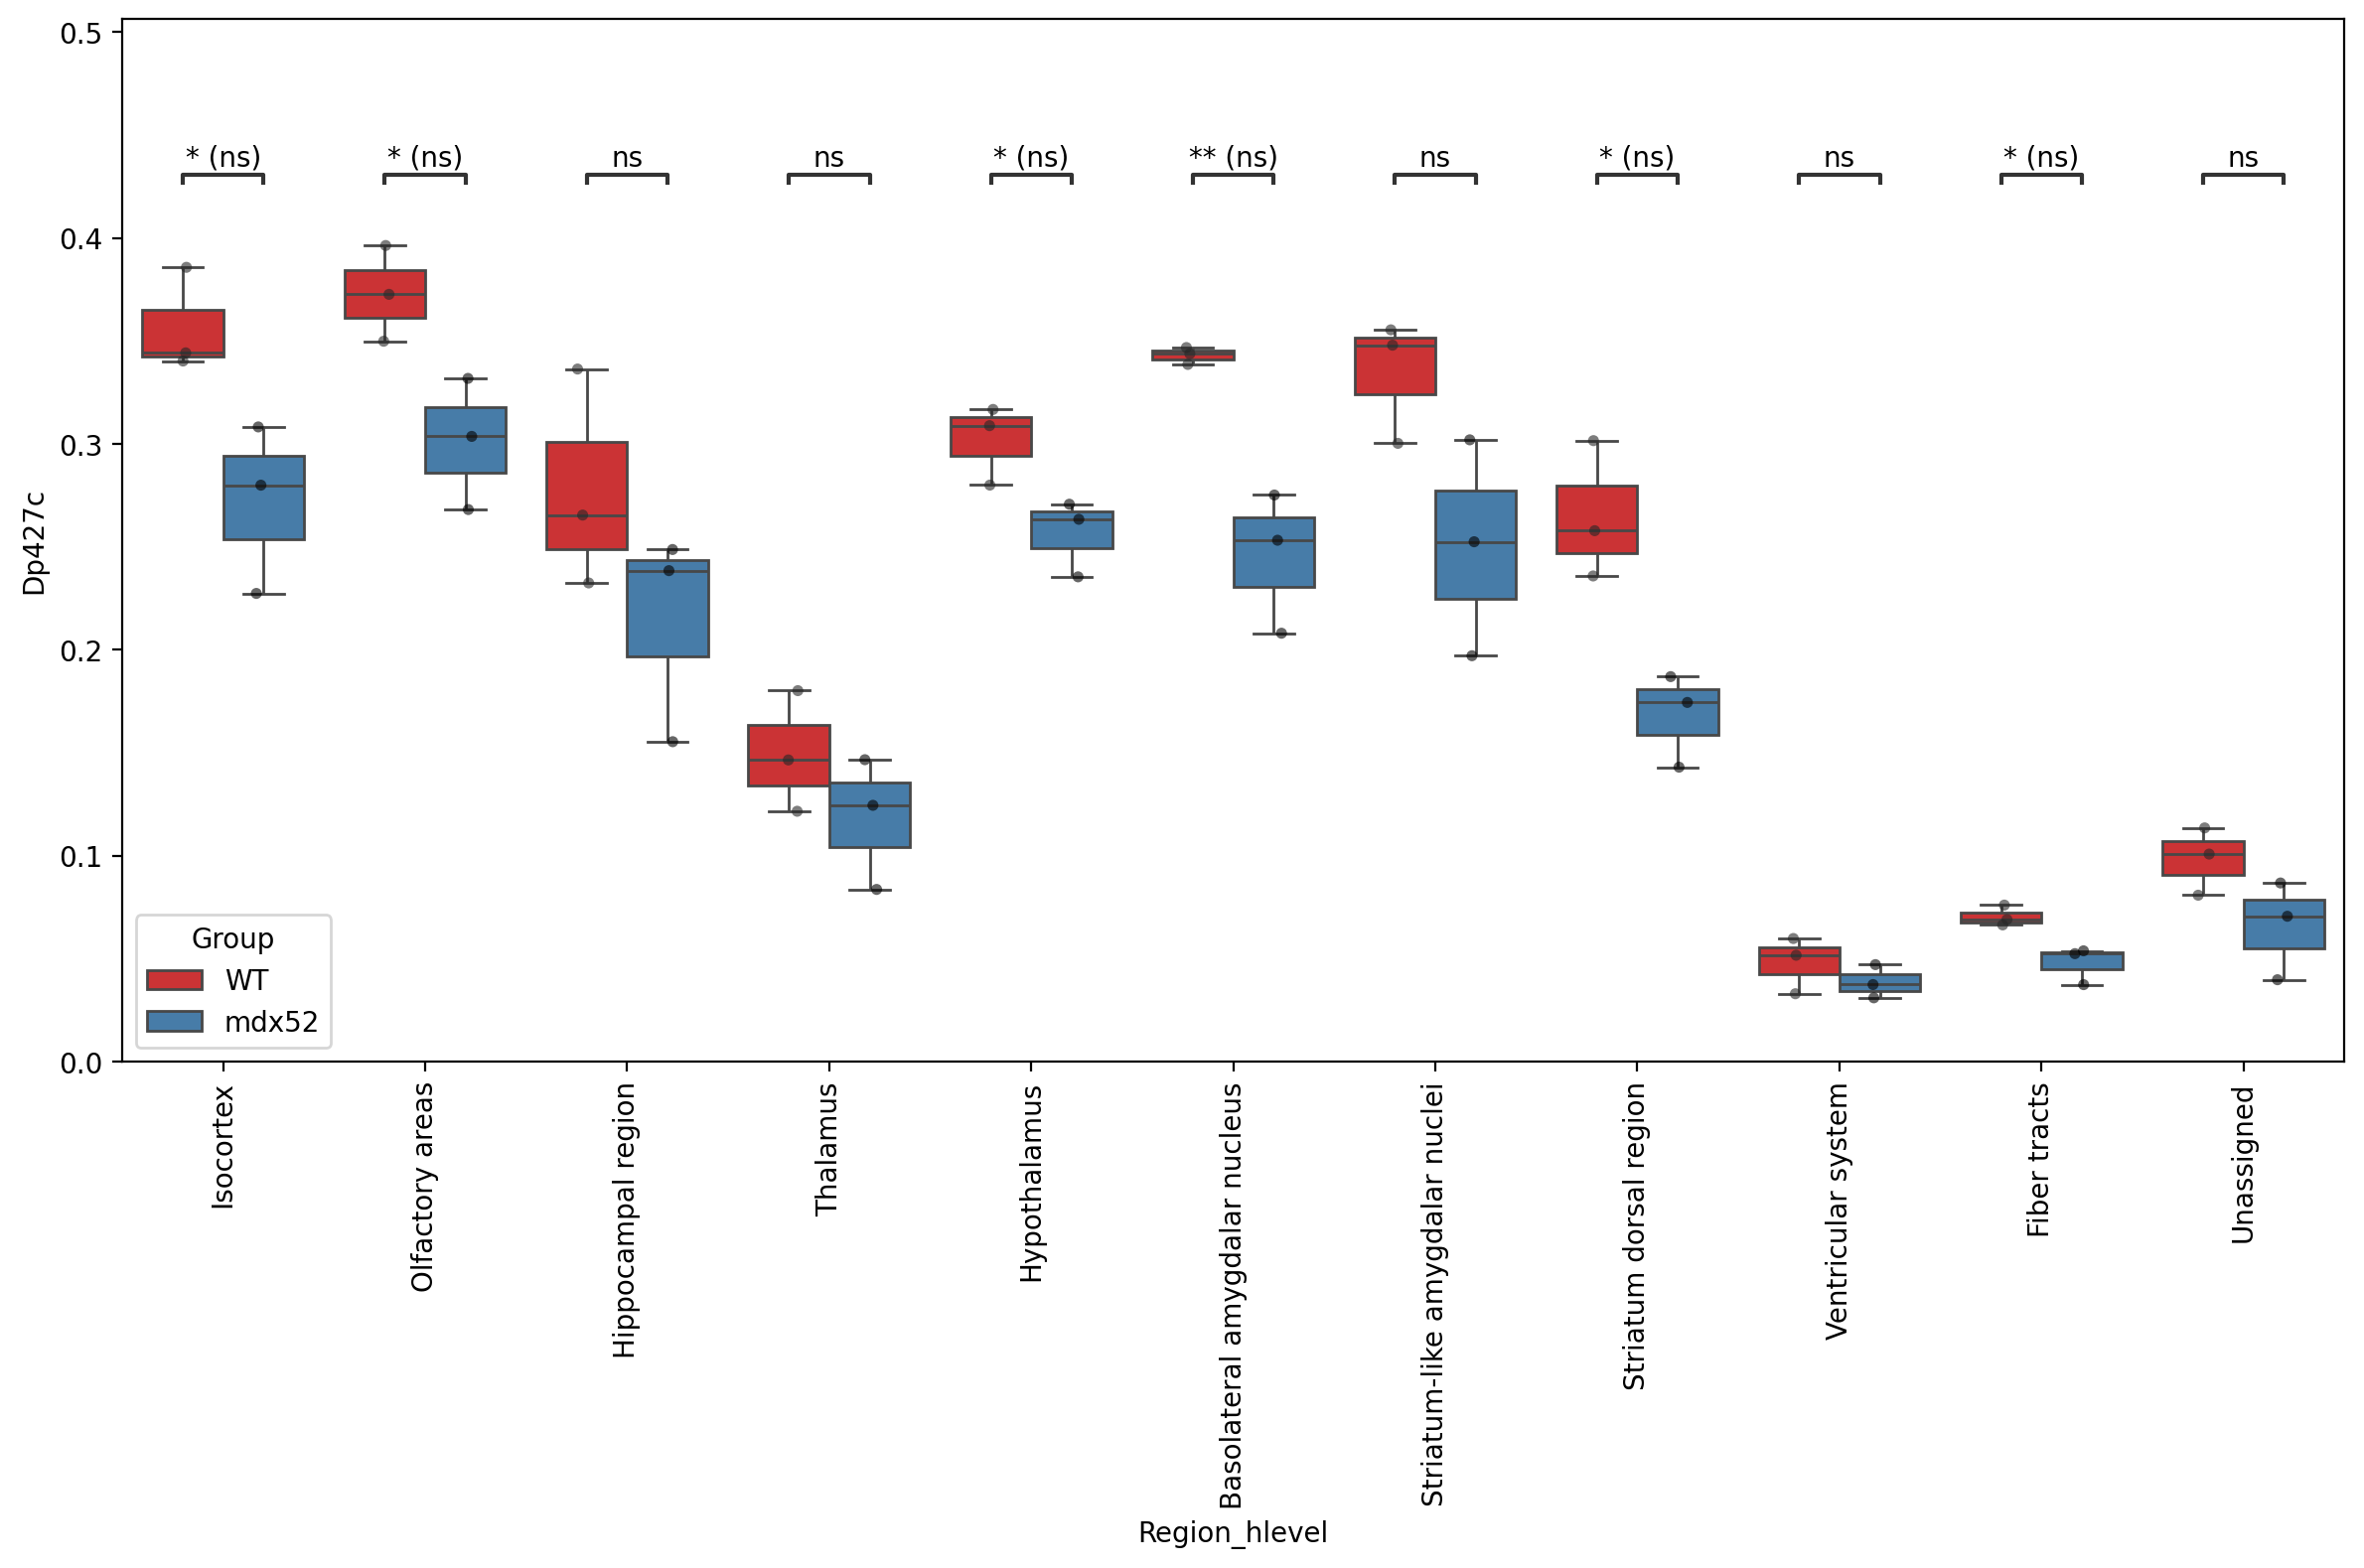

In [32]:
from statannotations.Annotator import Annotator
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Copy obs and add XX gene expression
df = adata.obs.copy()
df["Dp427c"] = adata[:, "Dp427c"].X.toarray().flatten()

# 2. Filter to keep only positive expression values

# 3. Compute mean XX expression per Sample

# Step 1: Group by Sample and Region to get mean expression
grouped_df = df.groupby(["Sample", "Region_hlevel"])["Dp427c"].mean().reset_index()

# Step 2: Map Group per Sample from original df
sample_to_group = df.drop_duplicates("Sample")[["Sample", "Group"]].set_index("Sample")["Group"]
grouped_df["Group"] = grouped_df["Sample"].map(sample_to_group)

# 4. Plot: boxplot + dotplot (stripplot)
plt.figure(figsize=(12, 8))

ax = sns.boxplot(data=grouped_df, x="Region_hlevel", y="Dp427c", hue="Group",
            palette="Set1", dodge=True, showfliers=False)

sns.stripplot(data=grouped_df, x="Region_hlevel", y="Dp427c", hue="Group",
              dodge=True, color="black", size=4, alpha=0.6)

# 5. Prepare statistical comparisons
group_list = grouped_df["Group"].unique()
if len(group_list) != 2:
    raise ValueError("Statannotations: This script assumes exactly two groups.")

regions = grouped_df["Region_hlevel"].unique()
pairs = [((region, group_list[0]), (region, group_list[1])) for region in regions]

annotator = Annotator(ax, pairs, data=grouped_df, x="Region_hlevel", y="Dp427c",
                      hue="Group", order=regions.tolist(), hue_order=group_list.tolist())

# Configure for unified clean position
annotator.configure(
    test='t-test_ind',
    text_format='star',
    loc='outside',               # Place annotations above plot
    verbose=0,
    line_offset=0.05,            # Vertical offset from top of box
    line_offset_to_group=True,   # Offset relative to group position
    line_height=0.01,
    fontsize=10,
    comparisons_correction="BH"
).apply_and_annotate()

# 6. Clean up legend
handles, labels = ax.get_legend_handles_labels()
n = len(group_list)
plt.legend(handles[:n], labels[:n], title="Group")

# 7. Tweak axis
plt.xticks(rotation=90)

# Extend y-axis to make space for annotation
y_max = grouped_df["Dp427c"].quantile(0.99)
plt.ylim(0, y_max * 1.3)  # 30% headroom for stars

##plt.title("Mean log expression of XX per sample with significance marks")
plt.tight_layout()
plt.show()

In [ ]:
from statannotations.Annotator import Annotator
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Copy obs and add XX gene expression
df = adata.obs.copy()
df["Dp427c"] = adata[:, "Dp427c"].X.toarray().flatten()

# 2. Filter to keep only positive expression values

# 3. Compute mean XX expression per Sample

# Step 1: Group by Sample and Region to get mean expression
grouped_df = df.groupby(["Sample"])["Dp427c"].mean().reset_index()

# Step 2: Map Group per Sample from original df
sample_to_group = df.drop_duplicates("Sample")[["Sample", "Group"]].set_index("Sample")["Group"]
grouped_df["Group"] = grouped_df["Sample"].map(sample_to_group)

# 4. Plot: boxplot + dotplot (stripplot)
plt.figure(figsize=(12, 8))

ax = sns.boxplot(data=grouped_df, x="", y="Dp427c", hue="Group",
            palette="Set1", dodge=True, showfliers=False)

sns.stripplot(data=grouped_df, x="Region", y="Dp427c", hue="Group",
              dodge=True, color="black", size=4, alpha=0.6)

# 5. Prepare statistical comparisons
group_list = grouped_df["Group"].unique()
if len(group_list) != 2:
    raise ValueError("Statannotations: This script assumes exactly two groups.")

regions = grouped_df["Region"].unique()
pairs = [((region, group_list[0]), (region, group_list[1])) for region in regions]

annotator = Annotator(ax, pairs, data=grouped_df, x="Region", y="Dp427c",
                      hue="Group", order=regions.tolist(), hue_order=group_list.tolist())

# Configure for unified clean position
annotator.configure(
    test='t-test',
    text_format='star',
    loc='outside',               # Place annotations above plot
    verbose=0,
    line_offset=0.05,            # Vertical offset from top of box
    line_offset_to_group=True,   # Offset relative to group position
    line_height=0.01,
    fontsize=10,
    comparisons_correction="BH"
).apply_and_annotate()

# 6. Clean up legend
handles, labels = ax.get_legend_handles_labels()
n = len(group_list)
plt.legend(handles[:n], labels[:n], title="Group")

# 7. Tweak axis
plt.xticks(rotation=90)

# Extend y-axis to make space for annotation
y_max = grouped_df["Dp427c"].quantile(0.99)
plt.ylim(0, y_max * 1.3)  # 30% headroom for stars

##plt.title("Mean log expression of XX per sample with significance marks")
plt.tight_layout()
plt.show()


In [38]:
import pandas as pd
from scipy.stats import mannwhitneyu

# Define the regions you want to test
selected_regions = ["Cortex L6a"]

# Get unique groups (must be 2 for Mann-Whitney)
group_list = grouped_df["Group"].unique()
if len(group_list) != 2:
    raise ValueError("Only two groups are supported for Mann-Whitney test.")

# Store results
results = []

for region in selected_regions:
    # Subset data to the current region
    region_data = grouped_df[grouped_df["Region"] == region]

    # Get values for the two groups
    group1_vals = region_data[region_data["Group"] == group_list[0]]["Dp427c"]
    group2_vals = region_data[region_data["Group"] == group_list[1]]["Dp427c"]

    # Only run test if both groups have at least 2 values
    if len(group1_vals) >= 2 and len(group2_vals) >= 2:
        stat, pval = mannwhitneyu(group1_vals, group2_vals, alternative="two-sided")
    else:
        stat, pval = float("nan"), float("nan")

    # Append to results list
    results.append({
        "Region": region,
        "Group1": group_list[0],
        "Group2": group_list[1],
        "U-statistic": stat,
        "p-value": pval,
        "n_Group1": len(group1_vals),
        "n_Group2": len(group2_vals)
    })

# Convert to DataFrame
result_df = pd.DataFrame(results)

# Display the result
print("\nMann-Whitney Test Results:")
print(result_df.to_string(index=False))


Mann-Whitney Test Results:
    Region Group1 Group2  U-statistic  p-value  n_Group1  n_Group2
Cortex L6a  mdx52     WT          0.0      0.1         3         3


/tmp/ipykernel_3535063/1330768108.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_df = df.groupby(["Sample", "Group", "Region"])["Dp427m"].mean().reset_index()
/tmp/ipykernel_3535063/1330768108.py:21: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=grouped_df, x="Region", y="Dp427m", hue="Group",


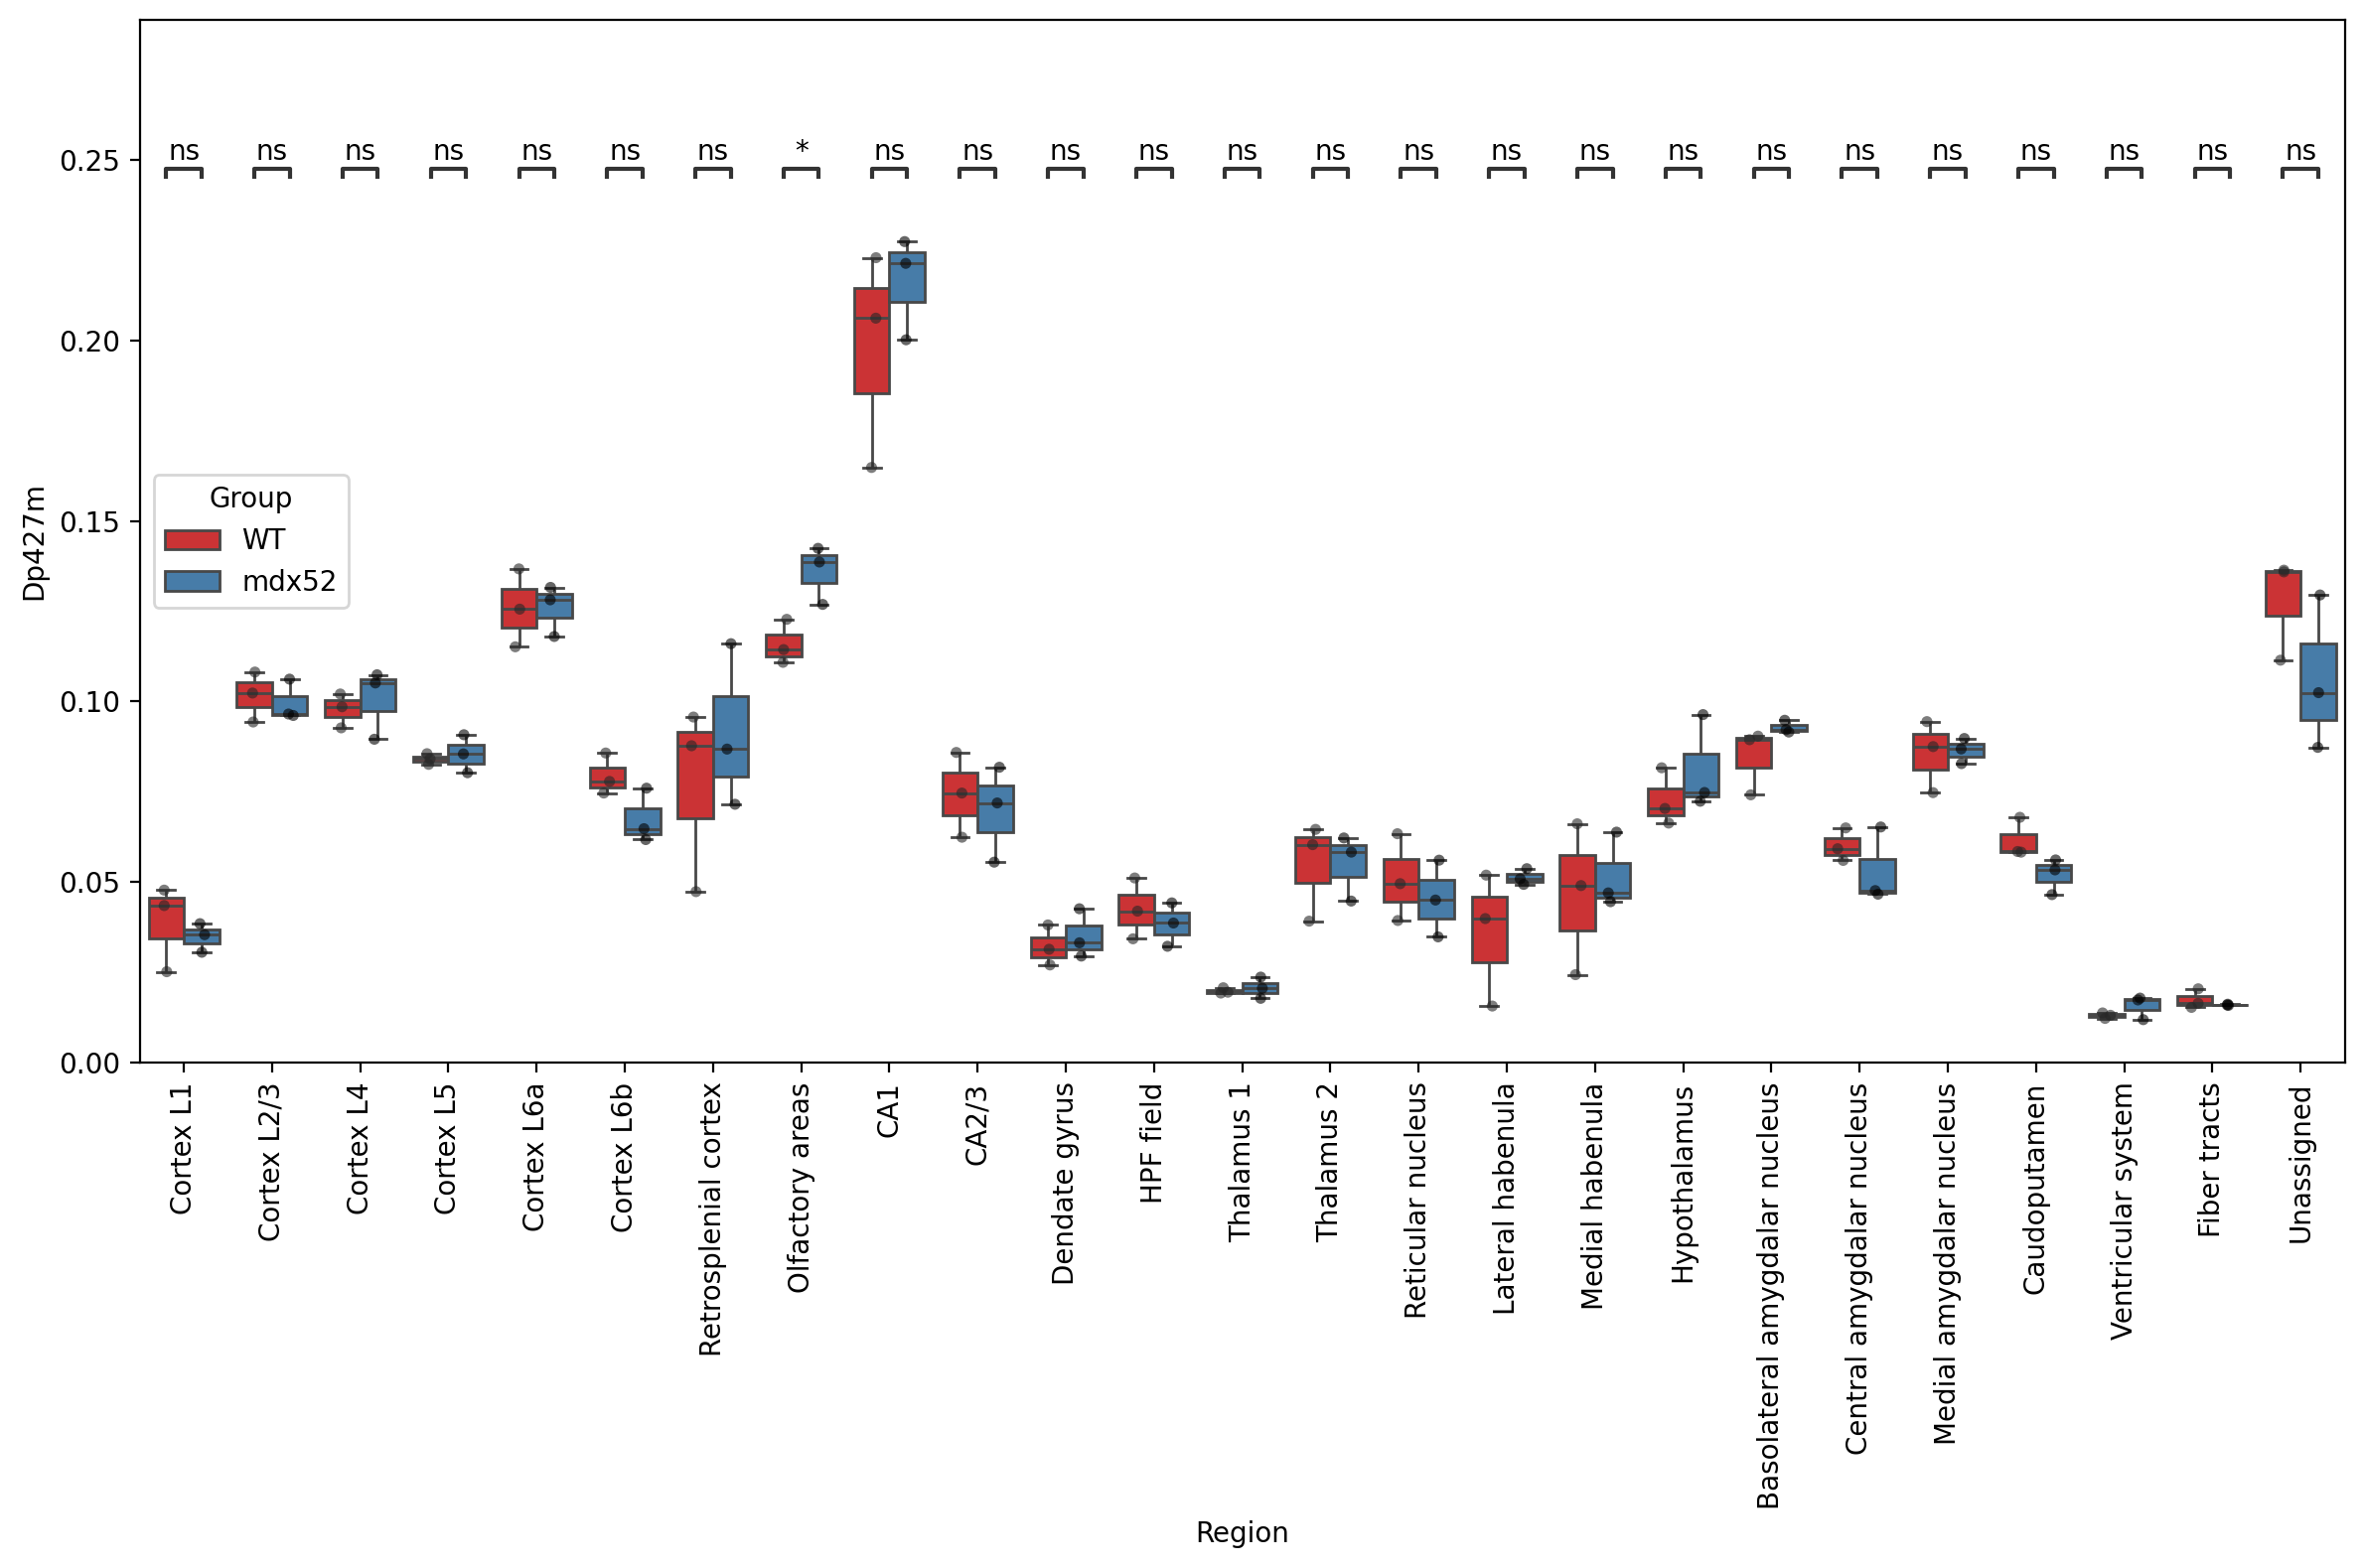

In [17]:
from statannotations.Annotator import Annotator
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Copy obs and add XX gene expression
df = adata.obs.copy()
df["Dp427m"] = adata[:, "Dp427m"].X.toarray().flatten()

# 2. Filter to keep only positive expression values

# 3. Compute mean XX expression per Sample
grouped_df = df.groupby(["Sample", "Group", "Region"])["Dp427m"].mean().reset_index()

# 4. Plot: boxplot + dotplot (stripplot)
plt.figure(figsize=(12, 8))

ax = sns.boxplot(data=grouped_df, x="Region", y="Dp427m", hue="Group",
            palette="Set1", dodge=True, showfliers=False)

sns.stripplot(data=grouped_df, x="Region", y="Dp427m", hue="Group",
              dodge=True, color="black", size=4, alpha=0.6)

# 5. Prepare statistical comparisons
group_list = grouped_df["Group"].unique()
if len(group_list) != 2:
    raise ValueError("Statannotations: This script assumes exactly two groups.")

regions = grouped_df["Region"].unique()
pairs = [((region, group_list[0]), (region, group_list[1])) for region in regions]

annotator = Annotator(ax, pairs, data=grouped_df, x="Region", y="Dp427m",
                      hue="Group", order=regions.tolist(), hue_order=group_list.tolist())

# Configure for unified clean position
annotator.configure(
    test='t-test_ind',
    text_format='star',
    loc='outside',               # Place annotations above plot
    verbose=0,
    line_offset=0.05,            # Vertical offset from top of box
    line_offset_to_group=True,   # Offset relative to group position
    line_height=0.01,
    fontsize=10
).apply_and_annotate()

# 6. Clean up legend
handles, labels = ax.get_legend_handles_labels()
n = len(group_list)
plt.legend(handles[:n], labels[:n], title="Group")

# 7. Tweak axis
plt.xticks(rotation=90)

# Extend y-axis to make space for annotation
y_max = grouped_df["Dp427m"].quantile(0.99)
plt.ylim(0, y_max * 1.3)  # 30% headroom for stars

##plt.title("Mean log expression of XX per sample with significance marks")
plt.tight_layout()
plt.show()

/tmp/ipykernel_3535063/1805350015.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_df = df.groupby(["Sample", "Group", "Region"])["Dp40"].mean().reset_index()
/tmp/ipykernel_3535063/1805350015.py:21: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=grouped_df, x="Region", y="Dp40", hue="Group",


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

CA2/3_WT vs. CA2/3_mdx52: t-test independent samples with Benjamini-Hochberg correction, P_val:4.079e-01 t=9.238e-01
Dendate gyrus_WT vs. Dendate gyrus_mdx52: t-test independent samples with Benjamini-Hochberg correction, P_val:1.357e-01 t=-1.864e+00
HPF field_WT vs. HPF field_mdx52: t-test independent samples with Benjamini-Hochberg correction, P_val:6.097e-01 t=5.531e-01
Thalamus 1_WT vs. Thalamus 1_mdx52: t-test independent samples with Benjamini-Hochberg correction, P_val:3.484e-01 t=1.061e+00
Thalamus 2_WT vs. Thalamus 2_mdx52: t-test independent samples with Benjamini-Hochberg correction, P_val:6.762e-01 t=4.498e-01
Reticular nucleus_WT vs. Reticular nucleus_mdx52: t-test independent samples with Benjamini-Hochberg correction, P_val:1.818e-02 (ns) t=3.858e+00
Lateral habenula_WT vs. Lateral 

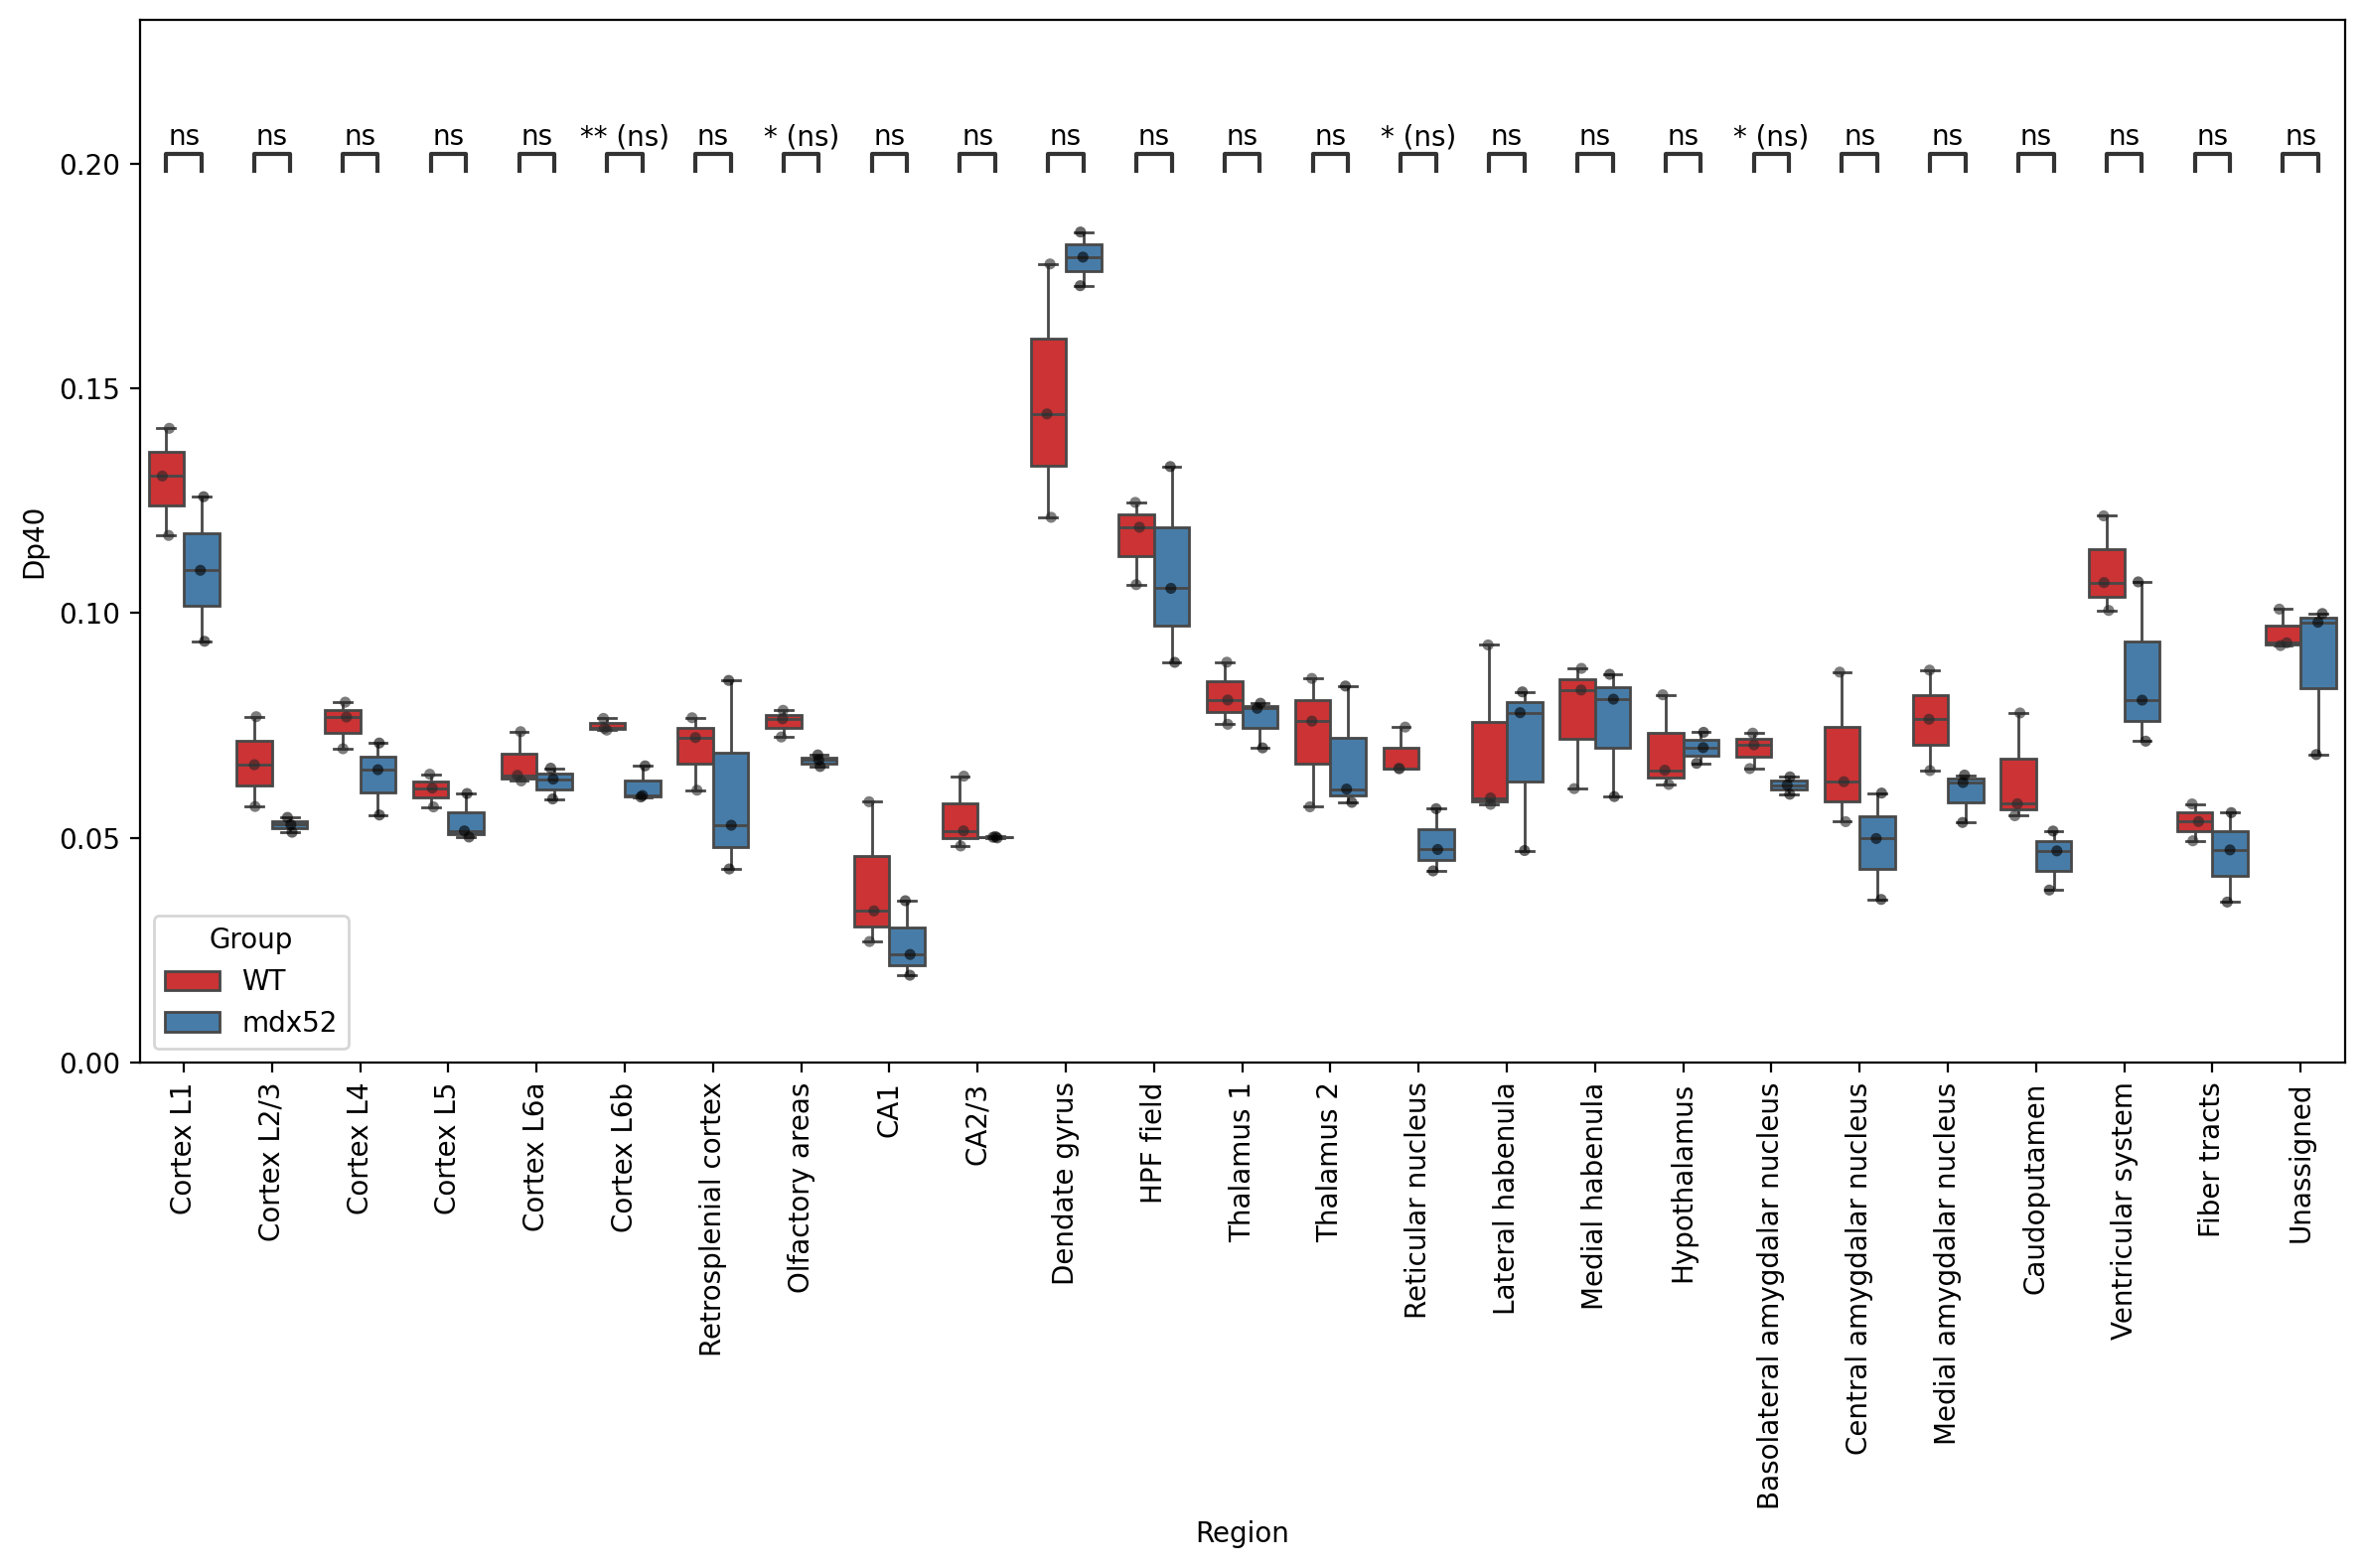

In [22]:
from statannotations.Annotator import Annotator
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Copy obs and add XX gene expression
df = adata.obs.copy()
df["Dp40"] = adata[:, "Dp40"].X.toarray().flatten()

# 2. Filter to keep only positive expression values

# 3. Compute mean XX expression per Sample
grouped_df = df.groupby(["Sample", "Group", "Region"])["Dp40"].mean().reset_index()

# 4. Plot: boxplot + dotplot (stripplot)
plt.figure(figsize=(12, 8))

ax = sns.boxplot(data=grouped_df, x="Region", y="Dp40", hue="Group",
            palette="Set1", dodge=True, showfliers=False)

sns.stripplot(data=grouped_df, x="Region", y="Dp40", hue="Group",
              dodge=True, color="black", size=4, alpha=0.6)

# 5. Prepare statistical comparisons
group_list = grouped_df["Group"].unique()
if len(group_list) != 2:
    raise ValueError("Statannotations: This script assumes exactly two groups.")

regions = grouped_df["Region"].unique()
pairs = [((region, group_list[0]), (region, group_list[1])) for region in regions]

annotator = Annotator(ax, pairs, data=grouped_df, x="Region", y="Dp40",
                      hue="Group", order=regions.tolist(), hue_order=group_list.tolist())

# Configure for unified clean position
annotator.configure(
    test='t-test_ind',
    text_format='star',
    loc='outside',
    line_offset=0.1,   # Try higher offset if boxes are tiny
    line_offset_to_group=True,
    line_height=0.02,
    fontsize=10,
    comparisons_correction="BH"
).apply_and_annotate()

# 6. Clean up legend
handles, labels = ax.get_legend_handles_labels()
n = len(group_list)
plt.legend(handles[:n], labels[:n], title="Group")

# 7. Tweak axis
plt.xticks(rotation=90)

# Extend y-axis to make space for annotation
# Compute max value and give padding
y_max = grouped_df["Dp40"].quantile(0.99)

# Ensure there's always headroom (e.g., at least 1.0 for vertical space)
plt.ylim(0, max(0.2, y_max * 1.3))

##plt.title("Mean log expression of XX per sample with significance marks")
plt.tight_layout()
plt.show()

In [10]:
output_dir = "/exports/humgen/qmao/Botxplot"
os.makedirs(output_dir, exist_ok=True)


# Step 1: Filter to the specific region

# Loop over each region
for region in adata.obs["Region"].unique():
    adata_region = adata[adata.obs["Region"] == region]

    # Step 2: Choose genes to plot
    genes_to_plot = ["Dp427c", "Dp427m","Dp427p",'Dp71_Dp40_firstexon',"Dp40"]  # replace with your genes

    # Step 3: Extract expression and metadata into a long dataframe
    df_list = []
    for gene in genes_to_plot:
        if gene in adata_region.var_names:
            expr = adata_region[:, gene].X.toarray().flatten() if hasattr(adata_region[:, gene].X, "toarray") else adata_region[:, gene].X.flatten()
            df_gene = pd.DataFrame({
                "Sample": adata_region.obs["Sample"].values,
                "Expression": expr,
                "Group": adata_region.obs["Group"].values,
                "Gene": gene
            })
            df_list.append(df_gene)
        else:
            print(f"{gene} not found in adata.var_names")

    df = pd.concat(df_list, axis=0)

    sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})

    # Step 2: Create a Sample → Group mapping
    sample_to_group = df[["Sample", "Group"]].drop_duplicates()

    # Step 3: Merge Group back into the avg DataFrame
    sample_expr_list_avg = sample_expr_list_avg.merge(sample_to_group, on="Sample", how="left")

    # Step 4: Make boxplot with hue
    plt.figure(figsize=(10, 8))
    sns.boxplot(data=sample_expr_list_avg, x="Gene", y="Expression", hue="Group",
                palette="Set1",order=genes_to_plot)
    sns.stripplot(data=sample_expr_list_avg, x="Gene", y="Expression", hue="Group",
                palette="Set1",order=genes_to_plot,dodge=True)
    plt.title(f"Gene expression in {region}")
    plt.tight_layout()
    safe_region = region.replace(" ", "_").replace("/", "_")
    plot_path = os.path.join(output_dir, f"{safe_region}_expression_boxplot.png")
    plt.savefig(plot_path, dpi=300)
    plt.close()

/tmp/ipykernel_2475501/2982378495.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})
/tmp/ipykernel_2475501/2982378495.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})
/tmp/ipykernel_2475501/2982378495.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future def

In [6]:
output_dir = "/exports/humgen/qmao/Botxplot"
os.makedirs(output_dir, exist_ok=True)


# Step 1: Filter to the specific region

# Loop over each region
for region in adata.obs["Class"].unique():
    adata_region = adata[adata.obs["Class"] == region]

    # Step 2: Choose genes to plot
    genes_to_plot = ["Dp427c", "Dp427m","Dp427p",'Dp71_Dp40_firstexon',"Dp40"]  # replace with your genes

    # Step 3: Extract expression and metadata into a long dataframe
    df_list = []
    for gene in genes_to_plot:
        if gene in adata_region.var_names:
            expr = adata_region[:, gene].X.toarray().flatten() if hasattr(adata_region[:, gene].X, "toarray") else adata_region[:, gene].X.flatten()
            df_gene = pd.DataFrame({
                "Sample": adata_region.obs["Sample"].values,
                "Expression": expr,
                "Group": adata_region.obs["Group"].values,
                "Gene": gene
            })
            df_list.append(df_gene)
        else:
            print(f"{gene} not found in adata.var_names")

    df = pd.concat(df_list, axis=0)

    sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})

    # Step 2: Create a Sample → Group mapping
    sample_to_group = df[["Sample", "Group"]].drop_duplicates()

    # Step 3: Merge Group back into the avg DataFrame
    sample_expr_list_avg = sample_expr_list_avg.merge(sample_to_group, on="Sample", how="left")

    # Step 4: Make boxplot with hue
    plt.figure(figsize=(10, 8))
    sns.boxplot(data=sample_expr_list_avg, x="Gene", y="Expression", hue="Group",
                palette="Set1",order=genes_to_plot)
    sns.stripplot(data=sample_expr_list_avg, x="Gene", y="Expression", hue="Group",
                palette="Set1",order=genes_to_plot,dodge=True)
    plt.title(f"Gene expression in {region}")
    plt.tight_layout()
    safe_region = region.replace(" ", "_").replace("/", "_")
    plot_path = os.path.join(output_dir, f"{safe_region}_expression_boxplot.png")
    plt.savefig(plot_path, dpi=300)
    plt.close()

/tmp/ipykernel_1403691/4163528433.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})
/tmp/ipykernel_1403691/4163528433.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})
/tmp/ipykernel_1403691/4163528433.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future def

In [5]:
sample_expr_list_avg

NameError: name 'sample_expr_list_avg' is not defined

In [10]:
output_dir = "/exports/humgen/qmao/Botxplot"
os.makedirs(output_dir, exist_ok=True)


# Step 1: Filter to the specific region

# Loop over each region
for region in adata.obs["Class"].unique():
    adata_region = adata

    # Step 2: Choose genes to plot
    genes_to_plot = ["Dp427c", "Dp427m","Dp427p",'Dp71_Dp40_firstexon',"Dp40"]  # replace with your genes

    # Step 3: Extract expression and metadata into a long dataframe
    df_list = []
    for gene in genes_to_plot:
        if gene in adata_region.var_names:
            expr = adata_region[:, gene].X.toarray().flatten() if hasattr(adata_region[:, gene].X, "toarray") else adata_region[:, gene].X.flatten()
            df_gene = pd.DataFrame({
                "Sample": adata_region.obs["Sample"].values,
                "Expression": expr,
                "Group": adata_region.obs["Group"].values,
                "Gene": gene
            })
            df_list.append(df_gene)
        else:
            print(f"{gene} not found in adata.var_names")

    df = pd.concat(df_list, axis=0)

    sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})

    # Step 2: Create a Sample → Group mapping
    sample_to_group = df[["Sample", "Group"]].drop_duplicates()

    # Step 3: Merge Group back into the avg DataFrame
    sample_expr_list_avg = sample_expr_list_avg.merge(sample_to_group, on="Sample", how="left")

    # Step 4: Make boxplot with hue
    plt.figure(figsize=(10, 8))
    sns.boxplot(data=sample_expr_list_avg, x="Gene", y="Expression", hue="Group",
                palette="Set1",order=genes_to_plot)
    sns.stripplot(data=sample_expr_list_avg, x="Gene", y="Expression", hue="Group",
                palette="Set1",order=genes_to_plot,dodge=True)
    plt.title(f"Gene expression in {region}")
    plt.tight_layout()
    safe_region = region.replace(" ", "_").replace("/", "_")
    plot_path = os.path.join(output_dir, f"{safe_region}_expression_boxplot.png")
    plt.savefig(plot_path, dpi=300)
    plt.close()

/tmp/ipykernel_2628216/227200111.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})
/tmp/ipykernel_2628216/227200111.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})
/tmp/ipykernel_2628216/227200111.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future defaul

In [11]:
sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})

# Step 2: Create a Sample → Group mapping
sample_to_group = df[["Sample", "Group"]].drop_duplicates()

# Step 3: Merge Group back into the avg DataFrame
sample_expr_list_avg = sample_expr_list_avg.merge(sample_to_group, on="Sample", how="left")

/tmp/ipykernel_2475501/1024533837.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})


In [12]:
df_gene 

,Sample,Expression,Group,Gene
0,895,0.000000,WT,Dp40
1,895,0.970737,WT,Dp40
2,895,0.000000,WT,Dp40
3,895,0.000000,WT,Dp40
4,895,0.000000,WT,Dp40
...,...,...,...,...
6187,18,0.000000,mdx52,Dp40
6188,18,0.000000,mdx52,Dp40
6189,18,0.000000,mdx52,Dp40
6190,18,0.000000,mdx52,Dp40


In [13]:
df

,Sample,Expression,Group,Gene
0,895,0.000000,WT,Dp427c
1,895,0.598806,WT,Dp427c
2,895,0.000000,WT,Dp427c
3,895,0.000000,WT,Dp427c
4,895,0.000000,WT,Dp427c
...,...,...,...,...
6187,18,0.000000,mdx52,Dp40
6188,18,0.000000,mdx52,Dp40
6189,18,0.000000,mdx52,Dp40
6190,18,0.000000,mdx52,Dp40


In [36]:
sample_expr_list.append(df)
    
    sample_expr_list= pd.concat(sample_expr_list , axis=0)
    
    # Group by Sample only, to get mean expression per sample
    sample_expr_list_avg = sample_expr_list.groupby(["Sample", "Group"], as_index=False).agg({"Expression": "mean"})

# Combine all gene results
df_plot = pd.concat(sample_expr_list_avg , axis=0)

# Step 4: Make boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_plot, x="Gene", y="Expression", hue="Group", palette="Set2")
sns.stripplot(data=df_plot, x="Gene", y="Expression", hue="Group", 
              dodge=True, color="black", size=3, alpha=0.6)

# Remove duplicate legend
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles[:len(df_plot["Group"].unique())], labels[:len(df_plot["Group"].unique())])

plt.title(f"Average expression per sample in {region}")
plt.ylabel("Mean expression (per sample)")
plt.tight_layout()
plt.show()

,expression,group,gene
0,0.699973,895,Dp427c
1,0.426818,895,Dp427c
2,0.920364,895,Dp427c
3,1.286327,895,Dp427c
4,0.000000,895,Dp427c
...,...,...,...
7347,0.000000,18,Dp40
7348,0.000000,18,Dp40
7349,0.000000,18,Dp40
7350,0.443718,18,Dp40


/tmp/ipykernel_2061916/425627458.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="group", y="mean_expression", palette="Set2")


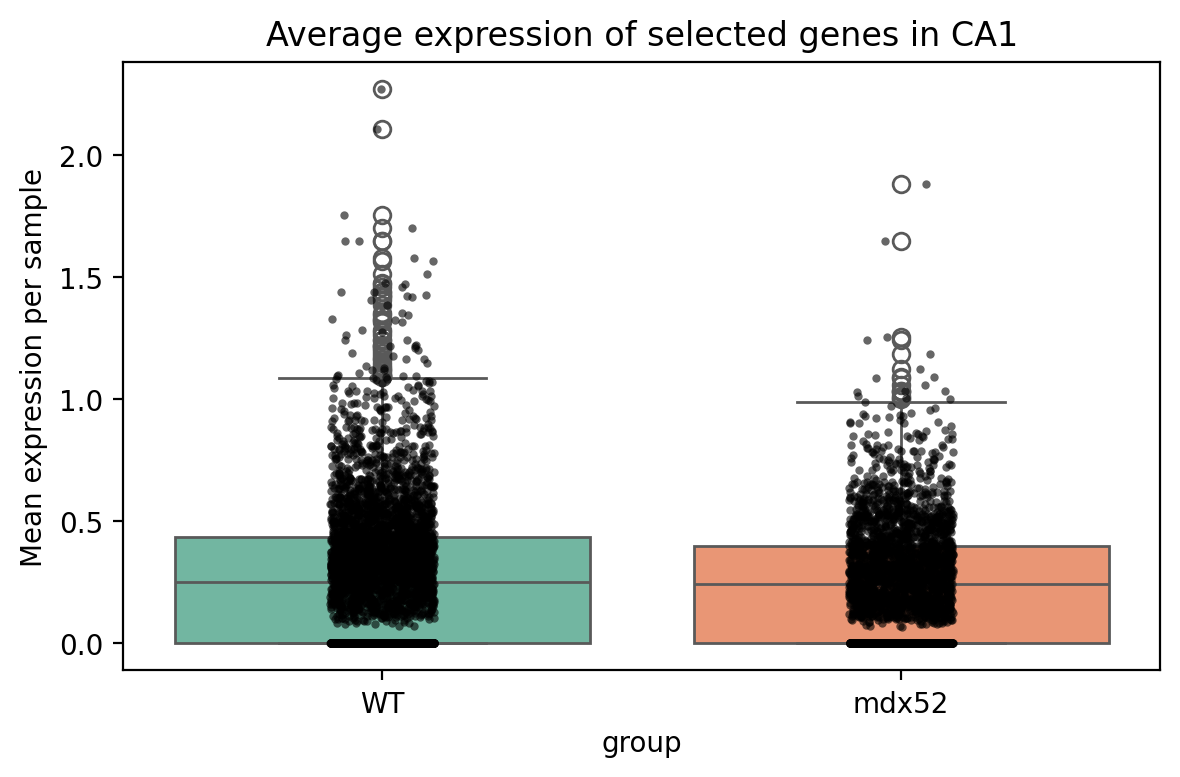

In [27]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Subset to the region of interest
region_of_interest = "CA1"  # change as needed
adata_region = adata[adata.obs["Region"] == region_of_interest]

# Step 2: Genes of interest
genes_to_plot = ["Dp427c", "Dp427m","Dp427p","Dp40"]  # replace with your genes
genes_available = [g for g in genes_to_plot if g in adata_region.var_names]

# Step 3: Get expression matrix for selected genes and compute mean per sample
if hasattr(adata_region[:, genes_available].X, "toarray"):
    expr_matrix = adata_region[:, genes_available].X.toarray()
else:
    expr_matrix = adata_region[:, genes_available].X

mean_expr_per_cell = expr_matrix.mean(axis=1)

# Step 4: Build a dataframe for plotting
df = pd.DataFrame({
    "mean_expression": mean_expr_per_cell,
    "group": adata_region.obs["Group"].values
})

# Step 5: Plot
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="group", y="mean_expression", palette="Set2")
sns.stripplot(data=df, x="group", y="mean_expression", color="black", size=3, jitter=True, alpha=0.6)
plt.title(f"Average expression of selected genes in {region_of_interest}")
plt.ylabel("Mean expression per sample")
plt.tight_layout()
plt.show()

In [31]:
selected_genes.unique()

array(['Pdzrn3', 'Neurod6', 'Lamp5', 'Hs3st2', 'Arhgap25', 'Nxph3',
       'Bhlhe22', 'Plekha2', 'Rasl10a', 'Hapln1', 'Bcl11b', 'Fezf2',
       'Rab3b', 'Gad2', 'Penk', 'Col6a1', 'Tmem255a', 'Calb2', 'Cdh4',
       'Cacna2d2', 'Plcxd3', 'Nwd2', 'Syt6', 'Kctd8', 'Prox1', 'Tmem163',
       'Nell1', 'Rfx4', 'Mog', 'Opalin', 'Sox10', 'Fn1', 'Igf2', 'Cldn5',
       'Cd300c2', 'Trem2', 'Laptm5'], dtype=object)

In [37]:
# List of sample names
sample_names = ["Sample_895", "Sample_894", "Sample_898","Sample_896","Sample_897","Sample_18","Sample_886","Sample_890","Sample_891","Sample_4","Sample_5","Sample_3","Sample_706","Sample_707","Sample_709T"]  # Replace with your sample names

genes = selected_genes.unique()

# Loop through each sample
for sample_name in sample_names:
    sample = globals()[sample_name]
    sc.pp.normalize_total(sample, inplace=True)
    sc.pp.log1p(sample)
    sample.var_names_make_unique()

    # Loop through each gene to generate and save the plot
    for gene in genes:
        sq.pl.spatial_scatter(
            sample,
            library_id="spatial",
            shape=None,
            color=[gene],  # Use the gene name in the color argument
            size=0.6,
            cmap="turbo",                               
            alpha=1,
            dpi=300
        )

        # Save the plot to a file
        output_dir=f"/exports/humgen/qmao/celltype_marker/{sample_name}/"
        os.makedirs(output_dir, exist_ok=True)
        plt.savefig(f"/exports/humgen/qmao/celltype_marker/{sample_name}/{gene}_spatial_scatter.tiff", dpi=300, bbox_inches="tight")
        plt.close()  # Close the plot after saving to avoid overlap in subsequent plots

In [5]:
# List of AnnData objects (e.g., adata1, adata2, ...)
adatas = [Sample_895, Sample_894, Sample_898,Sample_896,Sample_897,Sample_18,Sample_886,Sample_890,Sample_891,Sample_4,Sample_5,Sample_3,Sample_706,Sample_707,Sample_709T]  # Replace with your actual AnnData objects

# Initialize an empty list to store the counts per region for each sample in each AnnData object
region_counts = []

# Loop through each AnnData object to count occurrences of regions
for adata in adatas:
    # Count the occurrences of each region in the "Regions" column
    counts_per_region = adata.obs["Region"].value_counts()
    
    # Append the result (this will be a pandas Series for each adata)
    region_counts.append(counts_per_region)

# Convert the list of Series into a DataFrame
counts_df = pd.DataFrame(region_counts).transpose()

# Label columns (each corresponds to an AnnData object)
counts_df.columns = [f"adata{i+1}" for i in range(len(adatas))]
counts_df.columns = [adata.obs["Sample"].iloc[0] for adata in adatas]


In [14]:
import scanpy as sc
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

In [15]:
adata = Sample_895.concatenate(Sample_894,Sample_898,Sample_896,Sample_897,Sample_18)

/tmp/ipykernel_2475501/4106169230.py:1: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = Sample_895.concatenate(Sample_894,Sample_898,Sample_896,Sample_897,Sample_18)


In [16]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

In [17]:
rep_means

NameError: name 'rep_means' is not defined

In [18]:
# Step 1: Build a full expression DataFrame
expr_df = pd.DataFrame(
    adata.X.toarray(),  # or .todense() depending on your AnnData
    columns=adata.var_names,
    index=adata.obs[["Region", "Sample"]].apply(lambda x: f"{x['Region']}|{x['Sample']}", axis=1)
)

# Step 2: Recover Region and Sample as index levels
expr_df.index = expr_df.index.str.split("|", expand=True)
expr_df.index.names = ["Region", "Sample"]

# Step 3: Average gene expression per Region x Sample
rep_means = expr_df.groupby(["Region", "Sample"]).mean()

# Step 4: Add group info from adata.obs
group_info = adata.obs[["Region", "Sample", "Group"]].drop_duplicates()
group_info = group_info.set_index(["Region", "Sample"])

# Step 5: Join the group info
rep_means = rep_means.join(group_info)

In [19]:
pvals = []
genes = ["Dp427c", "Dp427m","Dp427p","Dp427p2","Dp71_Dp40_firstexon","Dp40",'Dystrophin_Exon2_29',
     'Dystrophin_Exon30_44',
     'Dystrophin_Exon45_49',
     'Dystrophin_Exon56_62',
     'Dystrophin_Exon79']

for gene in genes:
    group1 = rep_means[rep_means['Group'] == 'WT'][gene]
    group2 = rep_means[rep_means['Group'] == 'mdx52'][gene]
    stat, pval = ttest_ind(group1, group2, equal_var=False)
    pvals.append(pval)

# Multiple test correction
_, pvals_adj, _, _ = multipletests(pvals, method='bonferroni')

# Store results
stats_df = pd.DataFrame({
    'gene': genes,
    'pval': pvals,
    'pval_adj': pvals_adj
})

In [20]:
stats_df

,gene,pval,pval_adj
0,Dp427c,8.926466e-03,9.819112e-02
1,Dp427m,8.613364e-01,1.000000e+00
2,Dp427p,3.068878e-01,1.000000e+00
3,Dp427p2,4.146011e-01,1.000000e+00
4,Dp71_Dp40_firstexon,1.704653e-02,1.875119e-01
5,Dp40,6.796047e-02,7.475652e-01
6,Dystrophin_Exon2_29,5.550839e-03,6.105923e-02
7,Dystrophin_Exon30_44,3.461545e-03,3.807700e-02
8,Dystrophin_Exon45_49,1.417081e-09,1.558789e-08
9,Dystrophin_Exon56_62,3.453839e-12,3.799223e-11


In [21]:
# Melt pseudobulk matrix for plotting
long_df = rep_means.drop(columns='Group').reset_index().melt(id_vars='Sample', var_name='Gene', value_name='expression')
replicate_group = adata.obs[['Sample', 'Group']].drop_duplicates().set_index('Sample')
long_df['Group'] = long_df['Sample'].map(replicate_group['Group'])

# Add significance stars
def get_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

stats_df['star'] = stats_df['pval_adj'].apply(get_stars)

In [26]:
stats_df

,gene,pval,pval_adj,star
0,Dp427c,8.926466e-03,9.819112e-02,ns
1,Dp427m,8.613364e-01,1.000000e+00,ns
2,Dp427p,3.068878e-01,1.000000e+00,ns
3,Dp427p2,4.146011e-01,1.000000e+00,ns
4,Dp71_Dp40_firstexon,1.704653e-02,1.875119e-01,ns
5,Dp40,6.796047e-02,7.475652e-01,ns
6,Dystrophin_Exon2_29,5.550839e-03,6.105923e-02,ns
7,Dystrophin_Exon30_44,3.461545e-03,3.807700e-02,*
8,Dystrophin_Exon45_49,1.417081e-09,1.558789e-08,***
9,Dystrophin_Exon56_62,3.453839e-12,3.799223e-11,***


In [24]:
from statannotations.Annotator import Annotator
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Update rcParams for consistent formatting
plt.rcParams.update({
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'font.size': 6,
    'axes.titlesize': 6,
    'axes.labelsize': 6,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 6
})

mpl.rcParams['font.family'] = 'DejaVu Sans'  # or 'Arial'
mpl.rcParams['svg.fonttype'] = 'none'


# Pick genes to plot
genes_to_plot = stats_df['gene']  # or a subset like ['GeneA', 'GeneB']

for gene in genes_to_plot:
    fig, ax = plt.subplots(figsize=(1.4, 0.8))

    plot_df = long_df[long_df['Gene'] == gene]

    # Plot horizontal boxplot: x = expression, y = group
    sns.boxplot(data=plot_df, y='Group', x='expression', hue='Group',
                dodge=False, palette=["#66C2A5","#FC8D62"], ax=ax,showfliers=False,width=0.8,linewidth=0.3,fliersize=0)

    # Jittered points
    sns.stripplot(data=plot_df, y='Group', x='expression',
                  hue=None, color='black', size=1, jitter=True, ax=ax, orient='h')

    # Stats annotation using statannotations
    pairs = [('WT', 'mdx52')]  # adjust to your actual group names
    annotator = Annotator(ax, pairs, data=plot_df, x="expression", y="Group",
                          hue="Group", orient='h', comparisons_correction='Bonferroni')
    annotator.configure(loc='outside').set_pvalues_and_annotate([stats_df[stats_df["gene"]==gene]["pval_adj"].values[0]])

    # Fonts and labels
    ax.set_xlabel("Log Mean Expression")
    ax.set_ylabel("Group")
    ax.tick_params(axis='both')

    # Save and close
    plt.tight_layout()
    plt.savefig(f"/exports/humgen/qmao/{gene}_boxplot.svg",format="svg",dpi=300, bbox_inches='tight')
    plt.close()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. mdx52: Custom statistical test, P_val:9.819e-02
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. mdx52: Custom statistical test, P_val:1.000e+00
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. mdx52: Custom statistical test, P_val:1.000e+00
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. mdx52: Custom statistical test, P_val:1.000e+00
p-value anno

In [25]:
pvals = []
genes = ["Dp427c", "Dp427m","Dp427p","Dp427p2","Dp71_Dp40_firstexon","Dp40",'Dystrophin_Exon2_29',
     'Dystrophin_Exon30_44',
     'Dystrophin_Exon45_49',
     'Dystrophin_Exon56_62',
     'Dystrophin_Exon79']

for gene in genes:
    group1 = rep_means[rep_means['Group'] == 'WT'][gene]
    group2 = rep_means[rep_means['Group'] == 'mdx52'][gene]
    stat, pval = ttest_ind(group1, group2, equal_var=False)
    pvals.append(pval)

# Multiple test correction
_, pvals_adj, _, _ = multipletests(pvals, method='bonferroni')

# Store results
stats_df = pd.DataFrame({
    'gene': genes,
    'pval': pvals,
    'pval_adj': pvals_adj
})

In [14]:
# Melt pseudobulk matrix for plotting
long_df = rep_means.drop(columns='Group').reset_index().melt(id_vars='Sample', var_name='Gene', value_name='expression')
long_df['Group'] = long_df['Sample'].map(replicate_group['Group'])

# Add significance stars
def get_stars(p):
    if p < 0.001: return '***'
    elif p < 0.01: return '**'
    elif p < 0.05: return '*'
    else: return 'ns'

stats_df['star'] = stats_df['pval_adj'].apply(get_stars)

In [15]:
from statannotations.Annotator import Annotator
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Pick genes to plot
genes_to_plot = stats_df['gene']  # or a subset like ['GeneA', 'GeneB']

for gene in genes_to_plot:
    fig, ax = plt.subplots(figsize=(4, 2))

    plot_df = long_df[long_df['Gene'] == gene]

    # Plot horizontal boxplot: x = expression, y = group
    sns.boxplot(data=plot_df, y='Group', x='expression', hue='Group',
                dodge=False, palette=["#66C2A5","#FC8D62"], ax=ax, width=0.6, linewidth=1)

    # Jittered points
    sns.stripplot(data=plot_df, y='Group', x='expression',
                  hue=None, color='black', size=3, jitter=True, ax=ax, orient='h')

    # Stats annotation using statannotations
    pairs = [('WT', 'mdx52')]  # adjust to your actual group names
    annotator = Annotator(ax, pairs, data=plot_df, x="expression", y="Group",
                          hue="Group", orient='h', comparisons_correction='Bonferroni')
    annotator.configure(loc='outside').set_pvalues_and_annotate([stats_df[stats_df["gene"]==gene]["pval_adj"].values[0]])

    # Fonts and labels
    ax.set_xlabel("Log Mean Expression", fontsize=10)
    ax.set_ylabel("Group", fontsize=10)
    ax.tick_params(axis='both', labelsize=10)

    # Save and close
    plt.tight_layout()
    plt.savefig(f"/exports/humgen/qmao/{gene}_boxplot.tiff", dpi=300, bbox_inches='tight')
    plt.close()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. mdx52: Custom statistical test, P_val:1.000e+00
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. mdx52: Custom statistical test, P_val:1.000e+00
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. mdx52: Custom statistical test, P_val:1.000e+00
p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

WT vs. mdx52: Custom statistical test, P_val:1.000e+00
p-value anno

In [76]:
??annotator.configure

Signature: annotator.configure(**parameters)
Source:   
    def configure(self, **parameters):
        """
        * `alpha`: Acceptable type 1 error for statistical tests, default 0.05
        * `color`
        * `comparisons_correction`: Method for multiple comparisons correction.
            One of `statsmodels` `multipletests` methods (w/ default FWER), or
            a `ComparisonsCorrection` instance.
        * `correction_format`: How to format the star notation on the plot when
            the multiple comparisons correction method removes the significance
            * `default`: a ' (ns)' suffix is added, such as in printed output,
            corresponds to "{star} ({suffix})"
            * `replace`: the original star value is replaced with 'ns'
            corresponds to "{suffix}"
            * a custom formatting string using "{star}" for the original
            pvalue and '{suffix}' for 'ns'
        * `hide_non_significant`: hide annotations for non-significant pair
  

In [ ]:
# Loop over each region
for region in adata.obs["Region"].unique():
    adata_region = adata[adata.obs["Region"] == region]

    # Step 2: Choose genes to plot
    genes_to_plot = ["Dp427c", "Dp427m","Dp427p",'Dp71_Dp40_firstexon',"Dp40"]  # replace with your genes

    # Step 3: Extract expression and metadata into a long dataframe
    df_list = []
    for gene in genes_to_plot:
        if gene in adata_region.var_names:
            expr = adata_region[:, gene].X.toarray().flatten() if hasattr(adata_region[:, gene].X, "toarray") else adata_region[:, gene].X.flatten()
            df_gene = pd.DataFrame({
                "Sample": adata_region.obs["Sample"].values,
                "Expression": expr,
                "Group": adata_region.obs["Group"].values,
                "Gene": gene
            })
            df_list.append(df_gene)
        else:
            print(f"{gene} not found in adata.var_names")

    df = pd.concat(df_list, axis=0)

    sample_expr_list_avg = df.groupby(["Gene", "Sample"], as_index=False).agg({"Expression": "mean"})

    # Step 2: Create a Sample → Group mapping
    sample_to_group = df[["Sample", "Group"]].drop_duplicates()

    # Step 3: Merge Group back into the avg DataFrame
    sample_expr_list_avg = sample_expr_list_avg.merge(sample_to_group, on="Sample", how="left")

    # Step 4: Make boxplot with hue
    plt.figure(figsize=(10, 8))
    sns.boxplot(data=sample_expr_list_avg, x="Gene", y="Expression", hue="Group",
                palette="Set1",order=genes_to_plot)
    sns.stripplot(data=sample_expr_list_avg, x="Gene", y="Expression", hue="Group",
                palette="Set1",order=genes_to_plot,dodge=True)
    plt.title(f"Gene expression in {region}")
    plt.tight_layout()
    safe_region = region.replace(" ", "_").replace("/", "_")
    plot_path = os.path.join(output_dir, f"{safe_region}_expression_boxplot.png")
    plt.savefig(plot_path, dpi=300)
    plt.close()